# Introduction to Classification

In [1]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [2]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


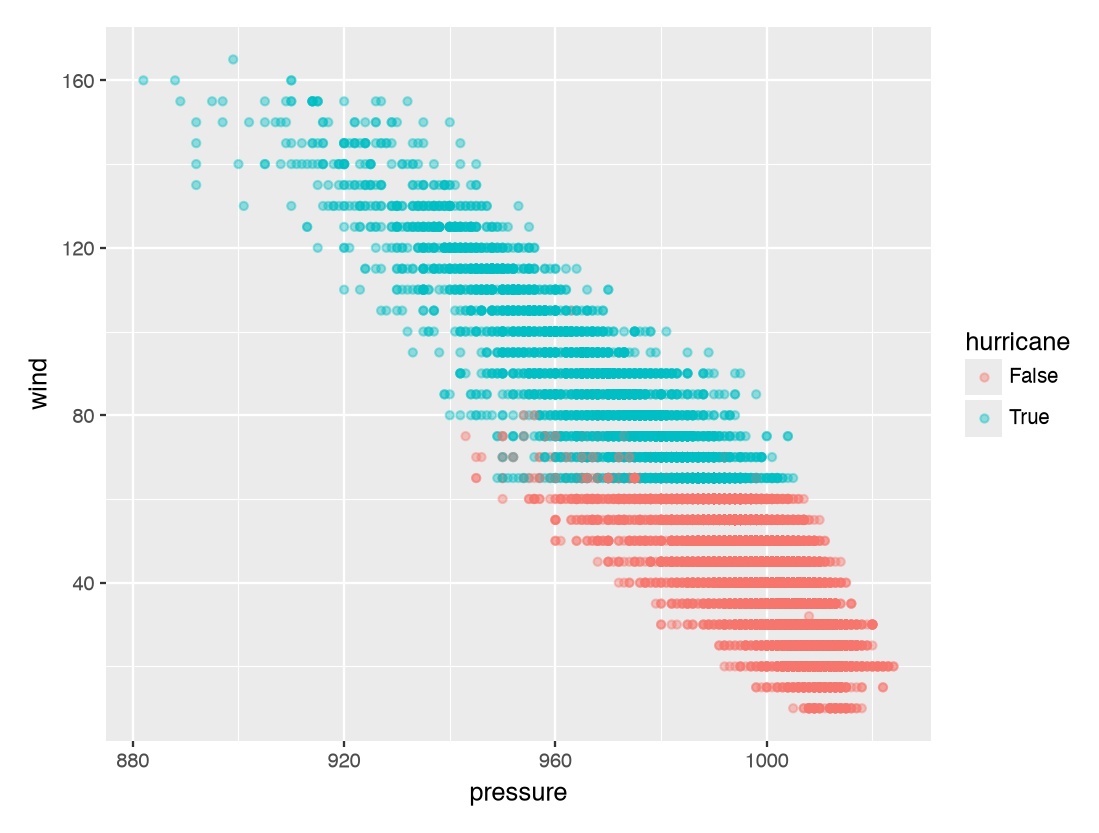

In [3]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

**DISCUSS WITH YOUR PARTNER.**

My rule is to predict a hurricane if the wind speed is 65 knots or higher. In the scatterplot, the hurricanes are all above about 65 knots and almost all non-hurricanes are below it. That gives high recall, because the rule catches nearly every hurricane. It also gives high precision, because very few non-hurricanes are above the line.

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  (4684 + 14254) / 19066 ≈ 99.3%. The rule correctly labels about 99.3% of storms as hurricane or not hurricane.

  b. training precision for the hurricane class  
  4684 / 4812 ≈ 97.3%. Of the storms the rule calls hurricanes, about 97.3% really are hurricanes.

  c. training recall for the hurricane class  
  4684 / 4684 = 100%. The rule catches 100% of the actual hurricanes.

  d. training F1 score for the hurricane class  
  98.7%. Precision and recall for hurricanes balance out to a very high score of about 98.7%.

  e. training precision for the non-hurricane class
  14254 / 14254 = 100%. Of the storms the rule calls non-hurricanes, 100% really are not hurricanes.

  f. training precision for the non-hurricane class  
  14254 / 14382 ≈ 99.1%. Of the storms that are not hurricanes, the rule correctly labels about 99.1% of them.

  g. training F1 score for the non-hurricane class  
  99.6%. Precision and recall for non-hurricanes balance out to about 99.6%.

In [4]:
df_storms["predicted"] = df_storms["wind"] >= 65

TP = (df_storms["predicted"] & df_storms["hurricane"]).sum()
FP = (df_storms["predicted"] & ~df_storms["hurricane"]).sum()
FN = (~df_storms["predicted"] & df_storms["hurricane"]).sum()
TN = (~df_storms["predicted"] & ~df_storms["hurricane"]).sum()
print(TP, FP, FN, TN)

4684 128 0 14254


3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

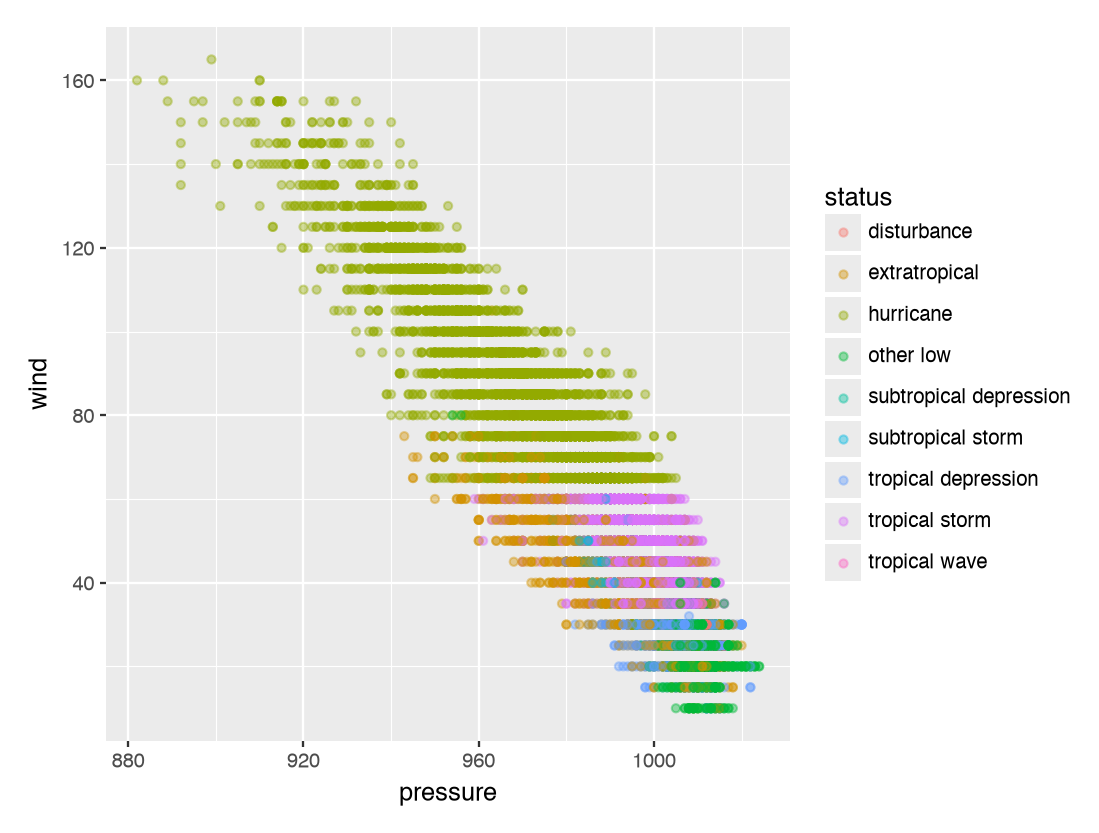

In [5]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

The model would predict extratropical. A storm with a pressure of 975 and a wind speed of 39 sits in the lower-left part of the cloud of points around wind = 40, and the dots there are mostly the orange-brown color for extratropical. Tropical storms (purple) at that wind speed usually have higher pressure, around 990 to 1005, so they are farther to the right. Wind speeds are recorded in steps of 5, so many storms are stacked on top of each other at wind = 40, and one dot can stand for several storms. That means the 10 closest storms are almost all extratropical, and the majority vote picks extratropical.

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

The classes with the lowest recall would be tropical wave and disturbance, followed by subtropical depression and subtropical storm. These classes have very few storms, only about 100 to 300 each. They also sit in the bottom-right corner of the plot (low wind, high pressure), right on top of thousands of tropical depressions and other lows. Because so many points are stacked on top of each other there, a tropical wave or disturbance will almost always have its 10 nearest neighbors come mostly from a bigger class. The model will outvote them and rarely predict them correctly. Hurricanes, on the other hand, have their own area at the top of the plot, so their recall should be very high.

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [6]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

X_train = df_titanic[["age", "gender", "class"]]
y_train = df_titanic["survived"]

ct = make_column_transformer(
    (StandardScaler(), ["age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["gender", "class"])
)

model = make_pipeline(ct, KNeighborsClassifier(n_neighbors=10))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['age','gender','class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

The model predicts that a 20-year-old female in first class would survive, with a predicted probability of survival of 1.0 (100%), because all 10 of her nearest neighbors survived. The model predicts that a 20-year-old female in third class would not survive, with a predicted probability of survival of only 0.2 (20%), because just 2 of her 10 nearest neighbors survived.

In [8]:
x_new = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

print(model.predict(x_new))
print(model.predict_proba(x_new))

[1 0]
[[0.  1. ]
 [0.8 0.2]]


3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_train_pred = model.predict(X_train)

print(precision_score(y_train, y_train_pred, pos_label=1))
print(recall_score(y_train, y_train_pred, pos_label=1))
print(f1_score(y_train, y_train_pred, pos_label=1))

0.8497757847533632
0.5330520393811533
0.6551426101987899


4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [10]:
print(precision_score(y_train, y_train_pred, pos_label=0))
print(recall_score(y_train, y_train_pred, pos_label=0))
print(f1_score(y_train, y_train_pred, pos_label=0))

0.8112563956793633
0.9551539491298527
0.8773439901629265


5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [11]:
p_survive = model.predict_proba(X_train)[:, 1]
y_pred_08 = (p_survive >= 0.8).astype(int)

print("Survivors:", precision_score(y_train, y_pred_08, pos_label=1),
      recall_score(y_train, y_pred_08, pos_label=1))
print("Non-survivors:", precision_score(y_train, y_pred_08, pos_label=0),
      recall_score(y_train, y_pred_08, pos_label=0))

Survivors: 0.9190031152647975 0.4149085794655415
Non-survivors: 0.7791932059447984 0.9825970548862115


6\. Plot the precision-recall curve for the survivors. Interpret what you see.

The curve goes down from left to right, which shows the tradeoff between precision and recall. When the threshold is high (like 0.9 or 1.0), precision is very high, about 94% to 100%, but recall is low, only about 20% to 36%, so the model is almost always right when it says someone survived but misses most survivors. As the threshold goes down, recall goes up, but precision drops. At a threshold of 0 the model predicts everyone survived, so recall reaches 100% and precision falls to about 32%, which is just the overall survival rate. The curve has only about 10 points because with 10 neighbors the probabilities can only be 0, 0.1, 0.2, and so on up to 1.0.

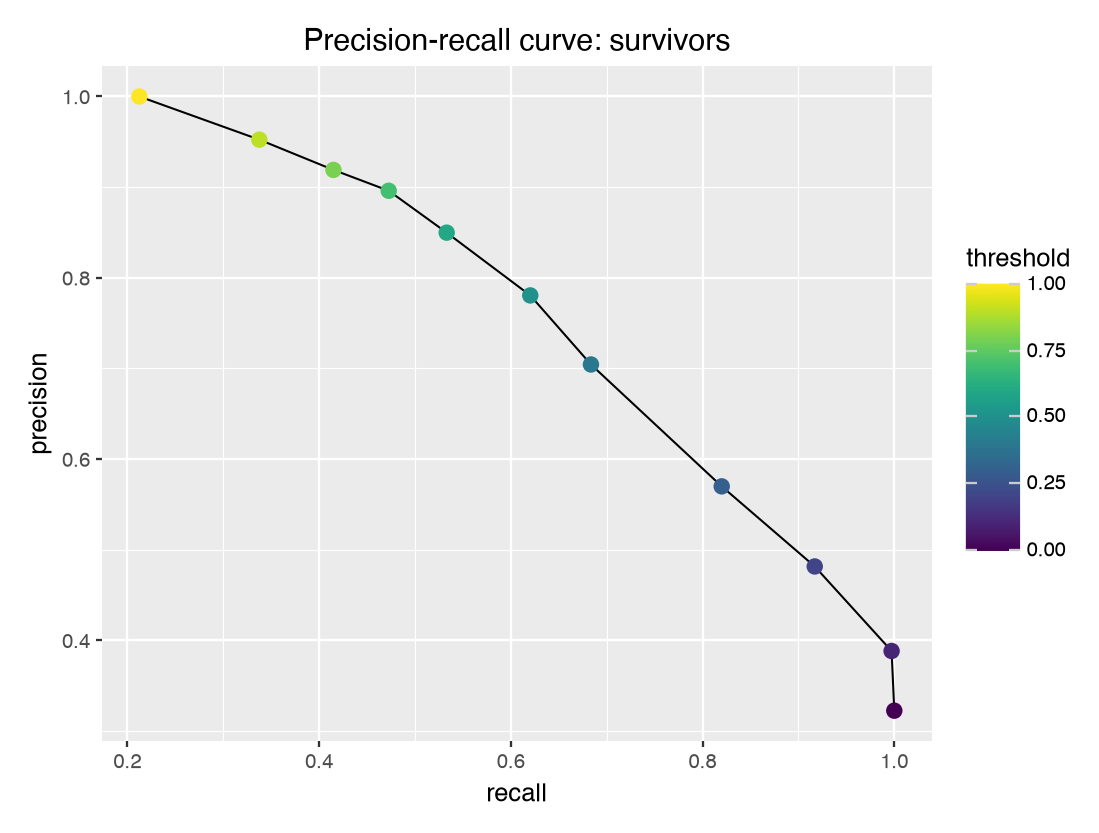

In [12]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_train, p_survive, pos_label=1)

df_pr = pd.DataFrame({
    "precision": precision[:-1],
    "recall": recall[:-1],
    "threshold": thresholds
})

(
    ggplot(df_pr, aes(x="recall", y="precision"))
    + geom_line()
    + geom_point(aes(color="threshold"), size=3)
    + labs(title="Precision-recall curve: survivors")
)

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

This curve also goes down from left to right, so there is still a tradeoff between precision and recall, but it stays much higher and flatter than the survivor curve. At high thresholds, precision is almost 99% with recall around 27%. At a threshold of 0.5, the model still has about 82% precision with 95% recall. Precision only drops to about 68% when the model predicts that everyone died, which is just the overall non-survival rate. This means the model is better at finding non-survivors than survivors. That makes sense, because most passengers did not survive, and many of them, like adult men in third class or the crew, are surrounded by neighbors who also died, so they are easy for the model to pick out.

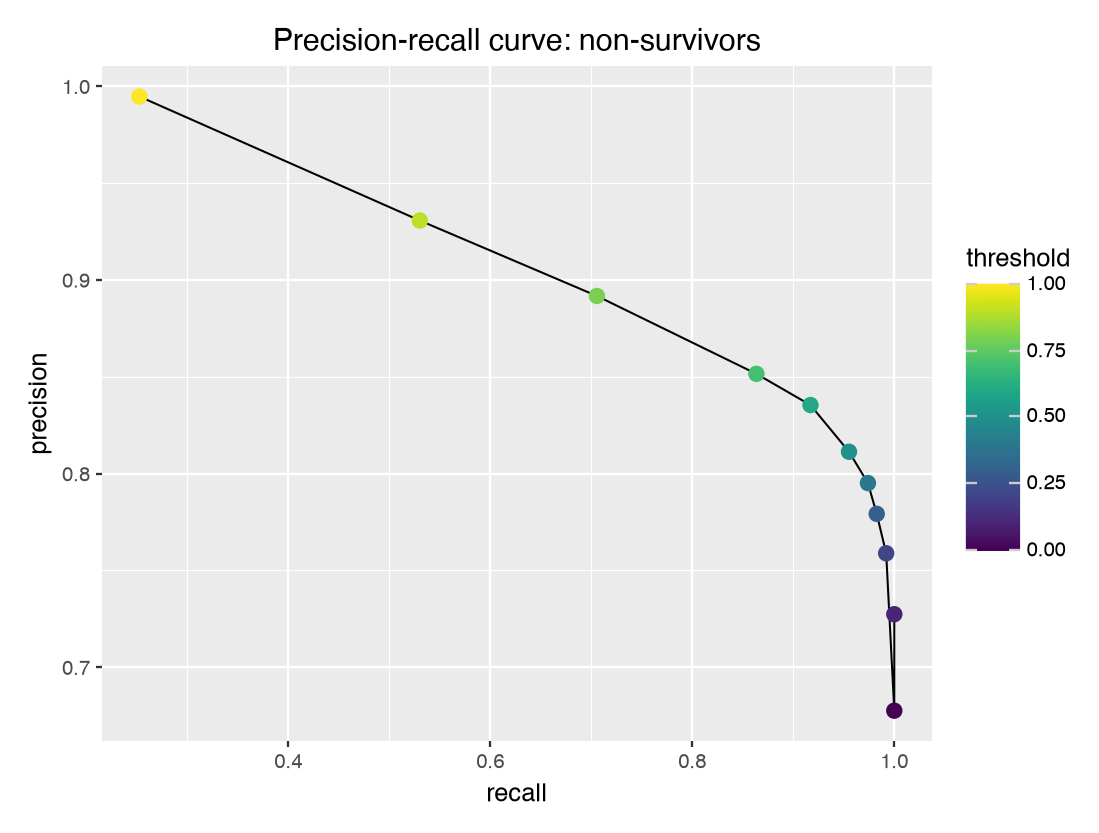

In [13]:
p_not_survive = model.predict_proba(X_train)[:, 0]

precision0, recall0, thresholds0 = precision_recall_curve(y_train, p_not_survive, pos_label=0)

df_pr0 = pd.DataFrame({
    "precision": precision0[:-1],
    "recall": recall0[:-1],
    "threshold": thresholds0
})

(
    ggplot(df_pr0, aes(x="recall", y="precision"))
    + geom_line()
    + geom_point(aes(color="threshold"), size=3)
    + labs(title="Precision-recall curve: non-survivors")
)